# Multi-Fidelity Method Comparison: Forrester Function

Example is based on the 2007 paper "Multi-fidelity optimization via surrogate modelling" by Forrester, Sobester, and Keane.

In [2]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans, kriging
import multi_fidelity_functions

Introduce the example function

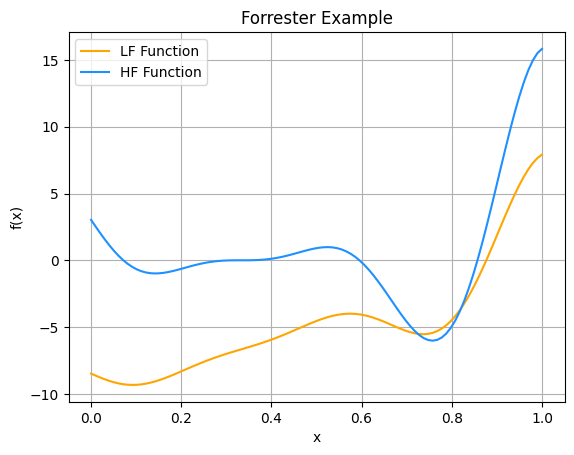

In [3]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

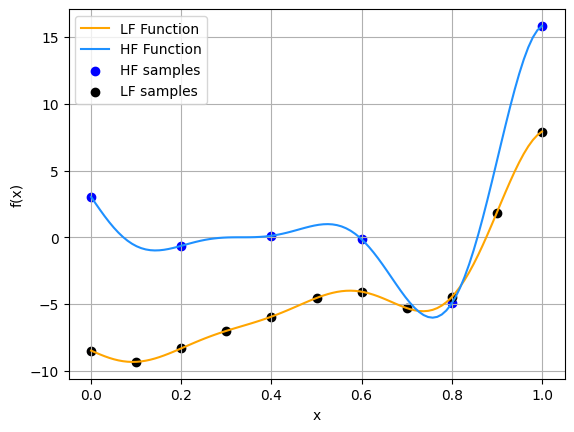

In [4]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11  # number of low fidelity points
n_hf = 6  # number of high fidelity points
n_test = 40  # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin, xmax, n_lf, dtype=np.float32).reshape(-1, 1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin, xmax, n_hf, dtype=np.float32).reshape(-1, 1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin, xmax, n_test, dtype=np.float32).reshape(-1, 1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name=plot_name)

plt.figure(plot_name)
plt.title("")
plt.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
plt.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
plt.legend()
plt.grid()
plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [5]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[8, 5],
    epochs_lf=100,
    epochs_mf=15000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.001,
    wd_mf=0.05,
)

TypeError: MFModel.__init__() missing 1 required positional argument: 'bounds'

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mf_model.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


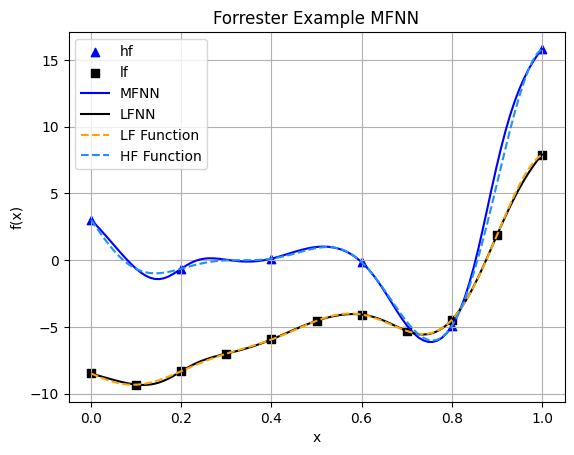

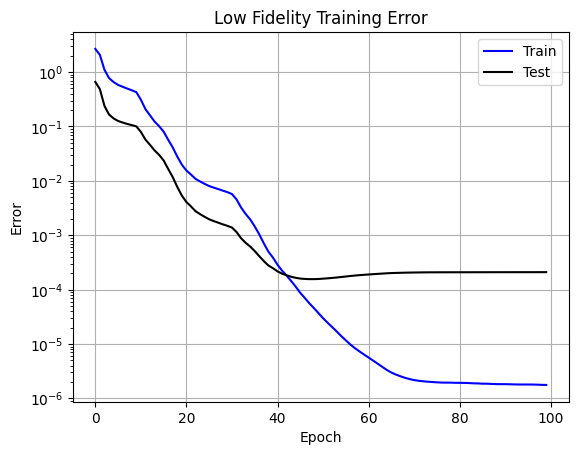

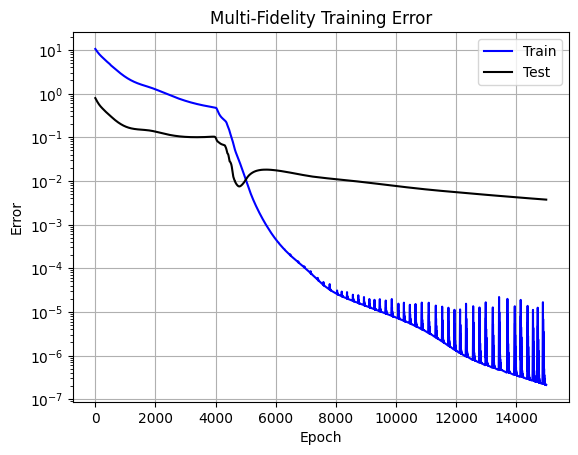

In [5]:
# Plot the results
plot_name = mf_example.name + " MFNN"

ax = mfnn_model.plot_data(plot_name)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="black",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [10]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf)
kriging_model = kriging.Kriging(X_hf, y_hf)

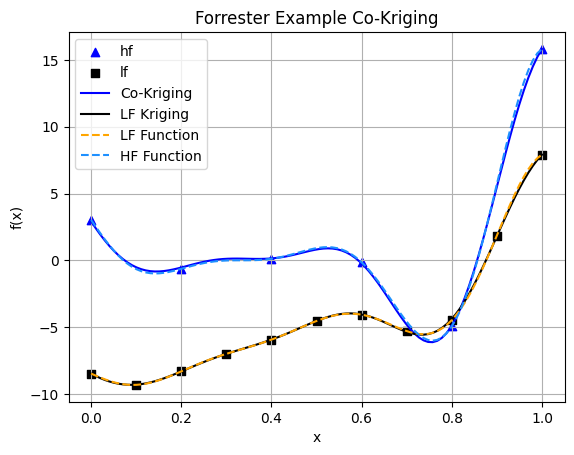

In [11]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

ax = cokriging_model.plot_data(plot_name)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [8]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=3,
    hidden_layers_lf=[],
    hidden_layers_mf=[],
    grid_lf=[2, 5, 10],
    grid_mf=[2, 3],
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=100,
    n_iter_mf=100,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.07e-01 | test_loss: 6.61e-01 | reg: 1.21e+01 | : 100%|█| 100/100 [00:03<00:00, 25.03


saving model version 0.1
saving model version 0.2


| train_loss: 9.85e-02 | test_loss: 1.26e-01 | reg: 1.22e+01 | : 100%|█| 100/100 [00:04<00:00, 21.59


saving model version 0.3
saving model version 0.4


| train_loss: 4.14e-02 | test_loss: 1.13e-01 | reg: 1.22e+01 | : 100%|█| 100/100 [00:07<00:00, 12.98


saving model version 0.5
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.98e-06 | test_loss: 9.81e-01 | reg: 1.16e+01 | : 100%|█| 100/100 [00:05<00:00, 18.31


saving model version 0.1
saving model version 0.2


| train_loss: 1.21e-06 | test_loss: 4.91e-01 | reg: 3.36e+01 | : 100%|█| 100/100 [00:04<00:00, 20.05

saving model version 0.3


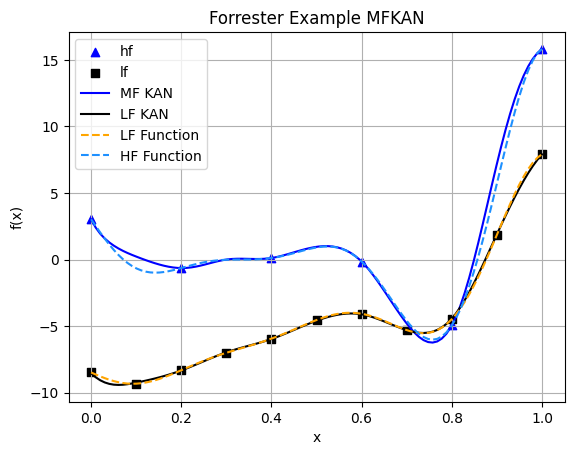

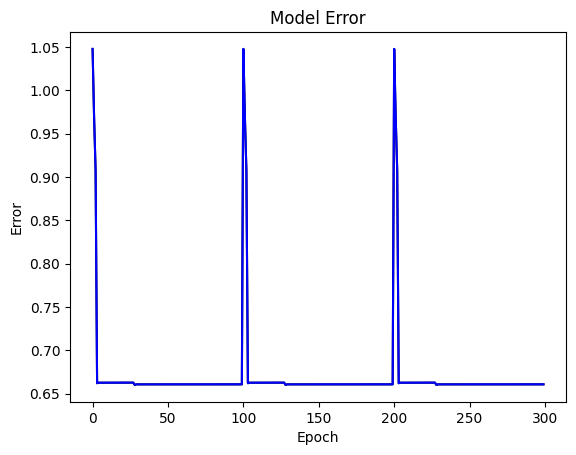

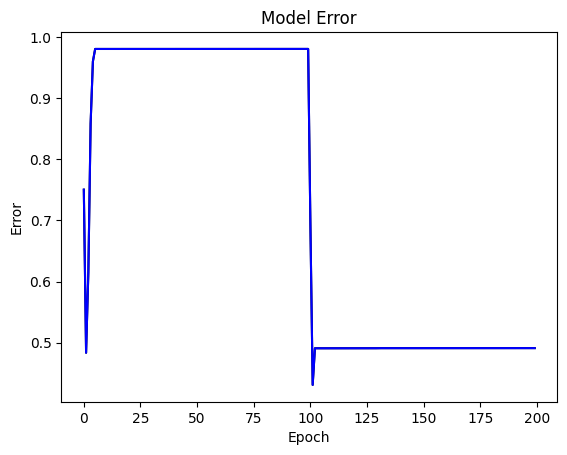

In [9]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

ax = mfkan_model.plot_data(plot_name)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

mfkan_model.plot_lf_fit_error()
mfkan_model.plot_mf_fit_error()

### Method Comparison

Compare the three different methods for their ability to fit the high fidelity function.

tensor(0.2356)


C:\Users\troyz\AppData\Local\Temp\ipykernel_24744\2675821921.py:107: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


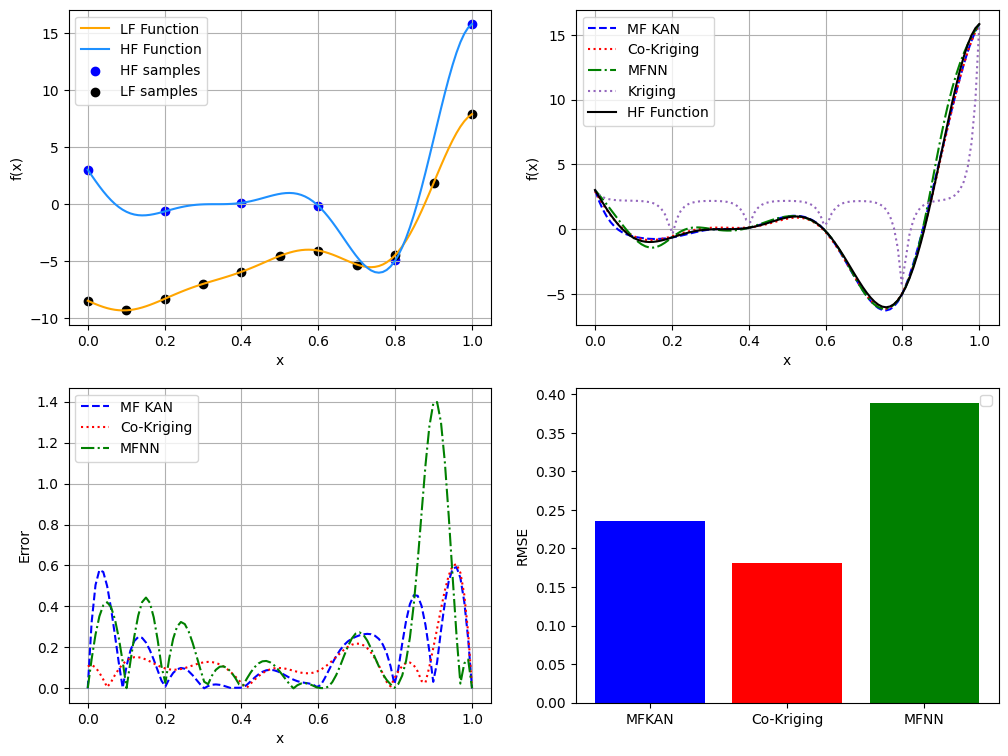

In [12]:
# Set figure size for plots
fig = plt.figure(figsize=(12,9))

# Plot the models and sample data
ax = fig.add_subplot(221)

plot_name = ""

ax = mf_example.plot_functions(name=plot_name, ax=ax)

ax.set_title(plot_name)
ax.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
ax.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
ax.grid()
ax.legend()

plot_name = ""

# Plot the model fits
ax = fig.add_subplot(222)

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = kriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="tab:purple",
    label="Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
ax.grid()
ax.legend()

# Plot the error comparison
ax = fig.add_subplot(223)
plot_name = ""

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax.grid()
ax.legend()


# Plot the error comparison
ax = fig.add_subplot(224)
plot_name = ""
names = ["MFKAN", "Co-Kriging", "MFNN"]
print(mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity))
error = [mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         cokriging_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         mfnn_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity)]
bar_colors = ['blue', 'red', 'green']
ax.bar(names, error, color=bar_colors)
ax.set_ylabel("RMSE")

plt.legend()
plt.show()

In [11]:
print(X_lf)
print(X_hf)

[[0. ]
 [0.1]
 [0.2]
 [0.3]
 [0.4]
 [0.5]
 [0.6]
 [0.7]
 [0.8]
 [0.9]
 [1. ]]
[[0. ]
 [0.2]
 [0.4]
 [0.6]
 [0.8]
 [1. ]]
